**Bloque 04. Visualización con Matplotlib**

Revisión y práctica del *Python Data Science Handbook*, de Jake VanderPlas.
Este cuaderno contiene explicaciones y ejemplos propios en español.

El objetivo es elegir una representación para cada pregunta: evolución, relación, distribución, variabilidad y estructura espacial.

Requisitos: Python 3, Jupyter, NumPy, pandas, Matplotlib y seaborn. Ejecuta las celdas en orden desde un kernel nuevo.
Los datos de los ejemplos son sintéticos, salvo que se indique otra procedencia.
Cada bloque es independiente de los demás.

**1. Figuras, ejes y datos**

Uso la interfaz de objetos: una figura contiene uno o varios ejes y cada eje
recibe datos, etiquetas y ajustes. Los valores representan una simulación de
horas de práctica y tareas completadas; no describen personas observadas.
La semilla fija mantiene los mismos datos al volver a ejecutar el cuaderno.

In [1]:
from io import BytesIO
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, FuncFormatter
import seaborn as sns

print('Matplotlib:', matplotlib.__version__, '| seaborn:', sns.__version__)
plt.rcParams.update({'figure.dpi': 90, 'font.size': 10})
rng = np.random.default_rng(42)
horas = rng.uniform(0, 8, 180)
tareas = np.maximum(0, 3 + 2 * horas + rng.normal(0, 2, horas.size))
tabla = pd.DataFrame({'horas': horas, 'tareas': tareas,
                      'grupo': np.where(horas < 4, 'Menos de 4 h', '4 h o más')})
tabla.head()

Matplotlib: 3.10.8 | seaborn: 0.13.2


,horas,tareas,grupo
0,6.191648,15.703280,4 h o más
1,3.511028,9.784778,Menos de 4 h
2,6.868783,17.309219,4 h o más
3,5.578944,16.769892,4 h o más
4,0.753419,4.945603,Menos de 4 h


**2. Líneas, leyendas, anotaciones y marcas**

Una línea resulta útil cuando el orden de los valores tiene significado.
Grafico dos trayectorias sintéticas por semana; las etiquetas y la leyenda
identifican las series. La anotación señala el máximo de una de ellas y
el localizador limita las marcas a semanas enteras.

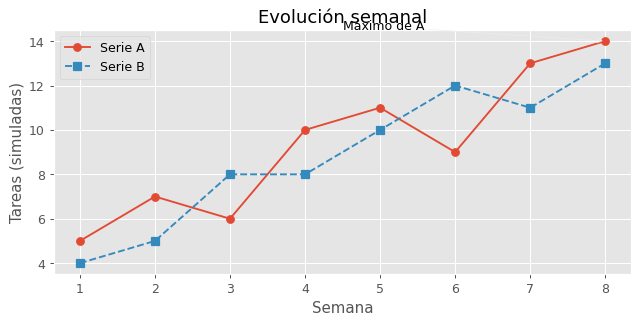

In [2]:
semanas = np.arange(1, 9)
serie_a = np.array([5, 7, 6, 10, 11, 9, 13, 14])
serie_b = np.array([4, 5, 8, 8, 10, 12, 11, 13])
with plt.style.context('ggplot'):
    fig, ax = plt.subplots(figsize=(7, 3.5), layout='constrained')
    ax.plot(semanas, serie_a, marker='o', label='Serie A')
    ax.plot(semanas, serie_b, marker='s', linestyle='--', label='Serie B')
    punto = np.argmax(serie_a)
    ax.annotate('Máximo de A', xy=(semanas[punto], serie_a[punto]),
                xytext=(4.5, 14.5), arrowprops={'arrowstyle': '->'})
    ax.set(xlabel='Semana', ylabel='Tareas (simuladas)', title='Evolución semanal')
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend(loc='upper left')
    plt.show()

**3. Dispersión y escala de color**

Cada punto representa un par de valores. El color codifica otra variable
cuantitativa, explicada por la barra de color. Una asociación visible no
demuestra causalidad; aquí la relación se programó al generar los datos.

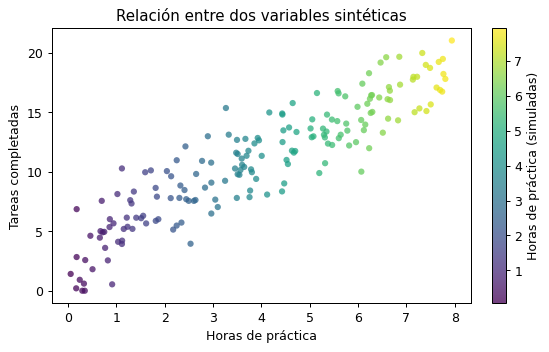

In [3]:
fig, ax = plt.subplots(figsize=(6, 3.8), layout='constrained')
puntos = ax.scatter(horas, tareas, c=horas, cmap='viridis', alpha=0.75,
                    s=25, edgecolors='none')
fig.colorbar(puntos, ax=ax, label='Horas de práctica (simuladas)')
ax.set(xlabel='Horas de práctica', ylabel='Tareas completadas',
       title='Relación entre dos variables sintéticas')
plt.show()

**4. Barras de error y bandas**

Simulo veinte repeticiones por nivel de práctica. Las barras y la banda
representan una desviación estándar muestral a cada lado de la media.
Expresan dispersión de las repeticiones, no un intervalo de confianza.
El significado de una barra de error debe indicarse siempre.

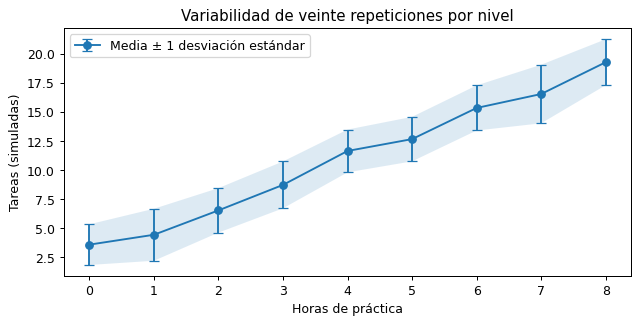

In [4]:
niveles = np.arange(0, 9)
repeticiones = 3 + 2 * niveles[:, None] + rng.normal(0, 2, (9, 20))
promedio = repeticiones.mean(axis=1)
dispersion = repeticiones.std(axis=1, ddof=1)
fig, ax = plt.subplots(figsize=(7, 3.5), layout='constrained')
ax.errorbar(niveles, promedio, yerr=dispersion, fmt='o-', capsize=4,
             label='Media ± 1 desviación estándar')
ax.fill_between(niveles, promedio - dispersion, promedio + dispersion,
                alpha=0.15)
ax.set(xlabel='Horas de práctica', ylabel='Tareas (simuladas)',
       title='Variabilidad de veinte repeticiones por nivel')
ax.legend()
plt.show()

**5. Histogramas, bins y paneles**

Un histograma resume frecuencias por intervalos. Comparo dos cantidades de
intervalos para los mismos datos; la forma aparente depende de esa decisión.
`density=True` normaliza el área total, no la suma de las alturas. Los ejes
compartidos facilitan comparar los dos paneles.

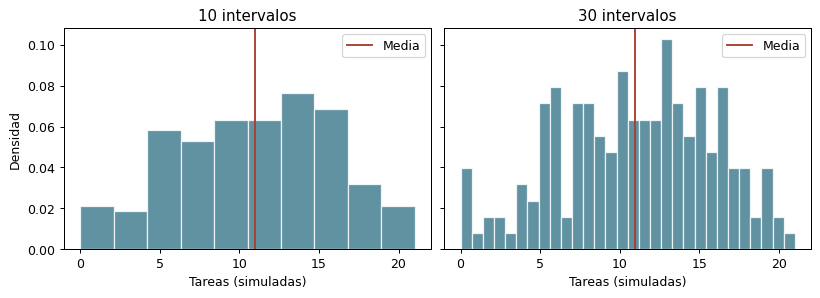

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharex=True, sharey=True,
                          layout='constrained')
for ax, bins in zip(axes, [10, 30]):
    ax.hist(tareas, bins=bins, density=True, color='#39778a',
            alpha=0.8, edgecolor='white')
    ax.axvline(np.mean(tareas), color='#a83f2f', label='Media')
    ax.set(title=f'{bins} intervalos', xlabel='Tareas (simuladas)')
    ax.legend()
axes[0].set_ylabel('Densidad')
plt.show()

alturas, bordes = np.histogram(tareas, bins=10, density=True)
assert np.isclose(np.sum(alturas * np.diff(bordes)), 1)

**6. Densidad bidimensional, imágenes y contornos**

`hist2d` resume cuántos pares caen en cada región. `contourf` muestra niveles
de una función evaluada sobre una cuadrícula. Ambos usan color, pero sus
barras describen magnitudes distintas. `imshow` permite representar una
matriz como imagen, especificando el rango espacial de sus celdas.

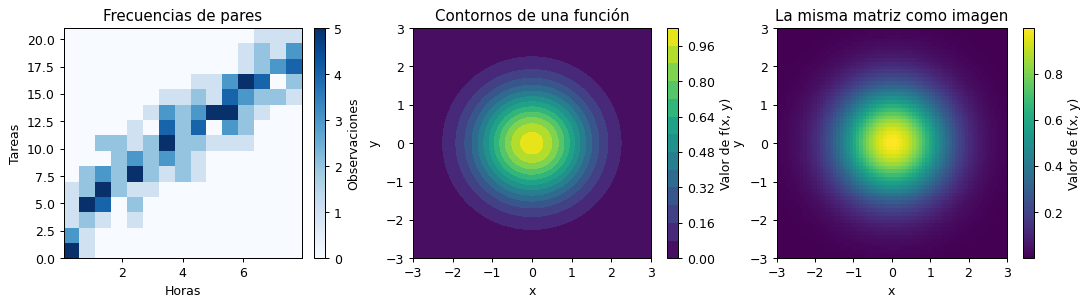

In [6]:
x = np.linspace(-3, 3, 70)
y = np.linspace(-3, 3, 60)
X, Y = np.meshgrid(x, y)
Z = np.exp(-(X**2 + Y**2) / 2)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3), layout='constrained')
hist = axes[0].hist2d(horas, tareas, bins=15, cmap='Blues')
fig.colorbar(hist[3], ax=axes[0], label='Observaciones')
axes[0].set(title='Frecuencias de pares', xlabel='Horas', ylabel='Tareas')
contornos = axes[1].contourf(X, Y, Z, levels=12, cmap='viridis')
fig.colorbar(contornos, ax=axes[1], label='Valor de f(x, y)')
axes[1].set(title='Contornos de una función', xlabel='x', ylabel='y')
imagen = axes[2].imshow(Z, origin='lower', extent=[-3, 3, -3, 3],
                        cmap='viridis', aspect='equal')
fig.colorbar(imagen, ax=axes[2], label='Valor de f(x, y)')
axes[2].set(title='La misma matriz como imagen', xlabel='x', ylabel='y')
plt.show()

**7. Superficie tridimensional**

Una superficie agrega una representación de altura a la misma función.
La perspectiva puede ocultar regiones; los contornos anteriores facilitan
leer niveles sin esa oclusión. La elección depende de la pregunta que se
quiera comunicar.

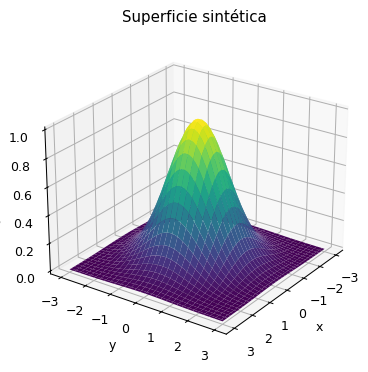

In [7]:
fig = plt.figure(figsize=(6, 4), layout='constrained')
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X, Y, Z, cmap='viridis', linewidth=0)
ax.set(xlabel='x', ylabel='y', zlabel='f(x, y)', title='Superficie sintética')
ax.view_init(elev=25, azim=35)
plt.show()

**8. Coordenadas geográficas y proyecciones**

La sección 04.13 del libro introduce proyecciones con Basemap. Este ejemplo
autocontenido transforma una cuadrícula sintética a Mercator mediante sus
fórmulas. Los ejes del segundo panel se expresan en coordenadas adimensionales
sobre una esfera de radio uno. La separación vertical cambia con la latitud.
Una nube de longitudes y latitudes por sí sola no define una proyección.

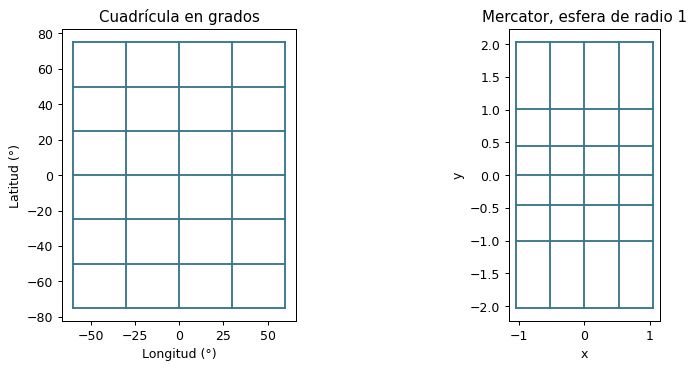

In [8]:
def mercator(lon, lat):
    """Proyección esférica para latitudes estrictamente entre -90 y 90."""
    lon, lat = np.asarray(lon), np.asarray(lat)
    if np.any(np.abs(lat) >= 90):
        raise ValueError('Mercator no admite los polos.')
    return np.deg2rad(lon), np.log(np.tan(np.pi / 4 + np.deg2rad(lat) / 2))

fig, axes = plt.subplots(1, 2, figsize=(9, 4), layout='constrained')
for lat in [-75, -50, -25, 0, 25, 50, 75]:
    lon_linea = np.linspace(-60, 60, 100)
    lat_linea = np.full_like(lon_linea, lat)
    axes[0].plot(lon_linea, lat_linea, color='#39778a')
    axes[1].plot(*mercator(lon_linea, lat_linea), color='#39778a')
for lon in [-60, -30, 0, 30, 60]:
    lat_linea = np.linspace(-75, 75, 100)
    lon_linea = np.full_like(lat_linea, lon)
    axes[0].plot(lon_linea, lat_linea, color='#39778a')
    axes[1].plot(*mercator(lon_linea, lat_linea), color='#39778a')
axes[0].set(title='Cuadrícula en grados', xlabel='Longitud (°)', ylabel='Latitud (°)')
axes[1].set(title='Mercator, esfera de radio 1', xlabel='x', ylabel='y')
for ax in axes:
    ax.set_aspect('equal')
plt.show()

**9. Visualización estadística con seaborn**

seaborn trabaja con columnas y categorías de un `DataFrame`. Una caja resume
la distribución de cada grupo y un diagrama de dispersión conserva los puntos.
Aquí los grupos se definen por las horas de práctica y no son grupos asignados
al azar, por lo que sus diferencias no estiman un efecto de tratamiento.

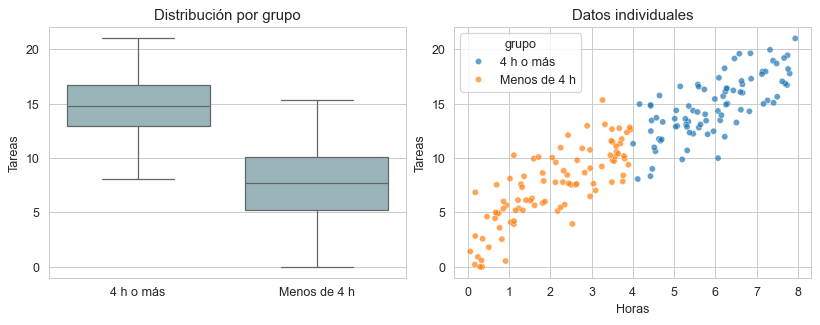

In [9]:
with sns.axes_style('whitegrid'):
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), layout='constrained')
    sns.boxplot(data=tabla, x='grupo', y='tareas', color='#94b9bf', ax=axes[0])
    sns.scatterplot(data=tabla, x='horas', y='tareas', hue='grupo',
                    alpha=0.7, s=25, ax=axes[1])
    axes[0].set(title='Distribución por grupo', xlabel='', ylabel='Tareas')
    axes[1].set(title='Datos individuales', xlabel='Horas', ylabel='Tareas')
    plt.show()

**10. Ejercicio resuelto: elegir y exportar una figura**

Pregunta: ¿cómo mostrar la distribución acumulada de las tareas simuladas?
Ordeno los datos y asigno a cada valor la proporción de observaciones que
queda hasta esa posición. El eje vertical usa un formato porcentual. La figura
se exporta a memoria en PNG para comprobar la salida sin crear archivos auxiliares.

Tamaño del PNG exportado: 32505 bytes


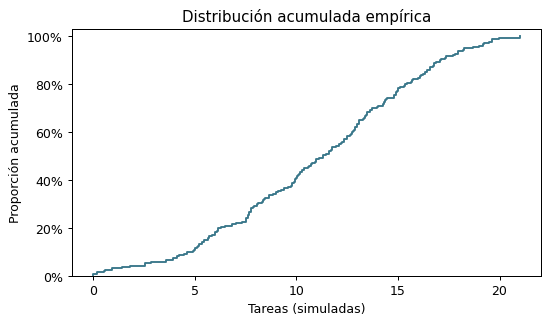

In [10]:
ordenados = np.sort(tareas)
acumulada = np.arange(1, len(tareas) + 1) / len(tareas)
fig, ax = plt.subplots(figsize=(6, 3.5), layout='constrained')
ax.step(ordenados, acumulada, where='post', color='#39778a')
ax.set(xlabel='Tareas (simuladas)', ylabel='Proporción acumulada',
       title='Distribución acumulada empírica', ylim=(0, 1.03))
ax.yaxis.set_major_formatter(FuncFormatter(lambda valor, _: f'{valor:.0%}'))
with BytesIO() as archivo_png:
    fig.savefig(archivo_png, format='png', dpi=150, bbox_inches='tight')
    print('Tamaño del PNG exportado:', len(archivo_png.getvalue()), 'bytes')
plt.show()
assert acumulada[-1] == 1

Una figura útil identifica variables, unidades y el significado de sus marcas.
El histograma muestra una distribución; la dispersión preserva pares; las
barras de error requieren una definición explícita. Las proyecciones y la
perspectiva modifican la representación, por lo que también forman parte
de la interpretación y deben elegirse con una pregunta concreta.

**Fuentes y correspondencia con el libro**

Referencia indicada en la consigna: VanderPlas, J. (2022). *Python Data Science Handbook: Essential Tools for Working with Data*. O’Reilly Media.

El material efectivamente revisado es la carpeta `notebooks_v1` del enlace de la consigna. Su prefacio identifica el copyright de 2016; por eso la referencia de 2022 y estos materiales no se presentan como una misma edición. Las secciones siguientes permiten consultar el desarrollo original de los temas practicados aquí.

[04.00-Introduction-To-Matplotlib](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/04.00-Introduction-To-Matplotlib.ipynb).

[04.01-Simple-Line-Plots](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/04.01-Simple-Line-Plots.ipynb).

[04.02-Simple-Scatter-Plots](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/04.02-Simple-Scatter-Plots.ipynb).

[04.03-Errorbars](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/04.03-Errorbars.ipynb).

[04.04-Density-and-Contour-Plots](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/04.04-Density-and-Contour-Plots.ipynb).

[04.05-Histograms-and-Binnings](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/04.05-Histograms-and-Binnings.ipynb).

[04.06-Customizing-Legends](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/04.06-Customizing-Legends.ipynb).

[04.07-Customizing-Colorbars](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/04.07-Customizing-Colorbars.ipynb).

[04.08-Multiple-Subplots](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/04.08-Multiple-Subplots.ipynb).

[04.09-Text-and-Annotation](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/04.09-Text-and-Annotation.ipynb).

[04.10-Customizing-Ticks](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/04.10-Customizing-Ticks.ipynb).

[04.11-Settings-and-Stylesheets](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/04.11-Settings-and-Stylesheets.ipynb).

[04.12-Three-Dimensional-Plotting](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/04.12-Three-Dimensional-Plotting.ipynb).

[04.13-Geographic-Data-With-Basemap](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/04.13-Geographic-Data-With-Basemap.ipynb).

[04.14-Visualization-With-Seaborn](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/04.14-Visualization-With-Seaborn.ipynb).

[04.15-Further-Resources](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/04.15-Further-Resources.ipynb).

Documentación de las bibliotecas utilizada para adaptar los ejemplos:

[Histogramas de Matplotlib](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.hist.html).

El texto original del libro declara licencia CC BY-NC-ND y su código, MIT. Las explicaciones y los ejercicios de este cuaderno son una elaboración nueva; las fuentes se conservan como referencia de estudio.